In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

In [2]:
temp_NE = xr.open_dataset('temp_corr_NE.nc').__xarray_dataarray_variable__
temp_WCE = xr.open_dataset('temp_corr_WCE.nc').__xarray_dataarray_variable__
temp_EE = xr.open_dataset('temp_corr_EE.nc').__xarray_dataarray_variable__
temp_SWE = xr.open_dataset('temp_corr_SWE.nc').__xarray_dataarray_variable__
temp_SEE = xr.open_dataset('temp_corr_SEE.nc').__xarray_dataarray_variable__

In [3]:
precip_NE = xr.open_dataset('precip_corr_NE.nc').tp
precip_WCE = xr.open_dataset('precip_corr_WCE.nc').tp
precip_EE = xr.open_dataset('precip_corr_EE.nc').tp
precip_SWE = xr.open_dataset('precip_corr_SWE.nc').tp
precip_SEE = xr.open_dataset('precip_corr_SEE.nc').tp

In [4]:
ds_oro = xr.load_dataset("target_variables/grib_files/orography_original_res.grib", engine="cfgrib")

Ignoring index file 'target_variables/grib_files/orography_original_res.grib.5b7b6.idx' incompatible with GRIB file


In [5]:
g = 9.80665

In [6]:
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

In [7]:
lon = ds_oro.longitude
lat = ds_oro.latitude
land_frac = ds_oro.lsm + ds_oro.cl
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)

In [8]:
map1 = temp_NE.where(land_frac*mount_filt>0.5)
map2 = precip_NE.where(land_frac*mount_filt>0.5)

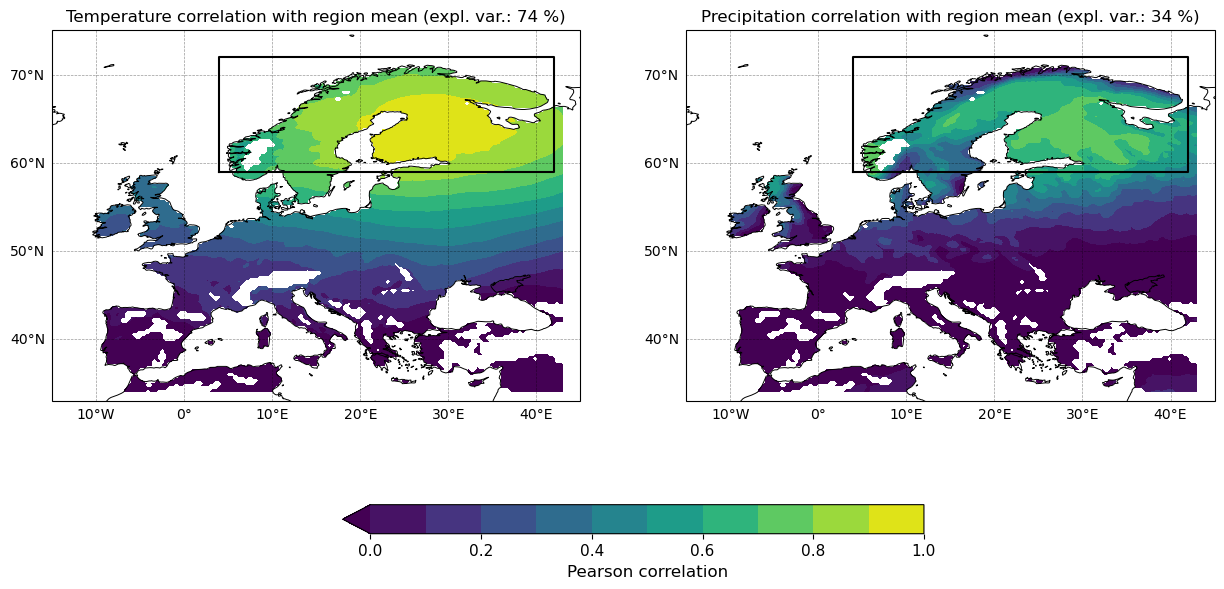

In [14]:
fig = plt.figure(figsize=(15,9))
levels = np.linspace(0, 1, 11)

ax1 = fig.add_subplot(121, projection=ccrs.PlateCarree())
ax1.set_extent((-15, 45, 33, 73))
ax1.coastlines(resolution='50m', linewidth=0.7)
gl = ax1.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
gl.right_labels = False
gl.top_labels = False
contf = ax1.contourf(lon, lat, map1, levels=levels, extend='min')
ax1.plot([4,42,42,4,4], [59,59,72,72,59], 'k')
ax1.set_title('Temperature correlation with region mean (expl. var.: 74 %)')

ax2 = fig.add_subplot(122, projection=ccrs.PlateCarree())
ax2.set_extent((-15, 45, 33, 73))
ax2.coastlines(resolution='50m', linewidth=0.7)
gl = ax2.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
gl.right_labels = False
gl.top_labels = False
contf = ax2.contourf(lon, lat, map2, levels=levels, extend='min')
ax2.plot([4,42,42,4,4], [59,59,72,72,59], 'k')
ax2.set_title('Precipitation correlation with region mean (expl. var.: 34 %)')
cbar = fig.colorbar(contf, ax=[ax1,ax2], location='bottom', shrink=0.5)
cbar.set_label('Pearson correlation',fontsize=12)
cbar.ax.tick_params(labelsize=11)
plt.savefig('correlations_NE.pdf', bbox_inches='tight')